# Y-factor: hot-wire temperature vs bias

**Measurement settings (always): RBW 1 MHz, VBW 1 kHz**, zero span, sample detector, LOG scale, read in W.
With VBW ≪ RBW the video filter fully averages the log-detected noise, so the reading is low by a fixed
10 log10(e)·γ ≈ 2.51 dB (Euler γ) whatever the noise level; that is the `LOG_VBW_CORR_DB` below.
Do not use VBW ≈ RBW (e.g. 3 MHz): the log averaging is then partial and the correction depends on the
filter shapes (measured ≈ 1.0 dB at VBW 3 MHz). The ENBW below is for RBW 1 MHz only.

Zero-span SA noise power vs noise source (hot wire) bias, from `y_factor_measurement` on the lab server.
The system gain G is taken as known (VNA S21 + qubit power calibration), so the hot-wire temperature
follows directly from the change of power with bias:

$$T_\mathrm{sys}(V) = \frac{P_\mathrm{read}(V)\cdot 10^{c/10}}{k_B\,B_\mathrm{ENBW}\,G}$$

$$T_{N,\mathrm{wire}}(V) = \frac{hf}{2k_B}\coth\frac{hf}{2k_B T_\mathrm{wire}(0)} + L\,\big[T_\mathrm{sys}(V) - T_\mathrm{sys}(0)\big]$$

$$T_{N,\mathrm{wire}} = \frac{hf}{2k_B}\coth\frac{hf}{2k_B T_e} \;\Rightarrow\; T_e$$

- $c$: correction for the SA reading noise low in LOG scale with VBW ≪ RBW
- $L$: loss between the hot wire and the plane G refers to (linear)
- $T_\mathrm{sys}(0)$ is taken per pass (its own zero-bias point), which removes slow drift between passes.

**Why the ENBW matters.** A CW tone sitting at the top of the RBW filter reads its full power whatever the filter
width (the SA is calibrated for sinusoids), so G, measured with a tone, has no bandwidth in it. Noise is spread
over all frequencies, and the filter collects $P = \int k_B T\,|H(f)|^2\,df = k_B T\,B_\mathrm{ENBW}$: the ENBW is
how many Hz of noise the filter takes in. Here G comes from a tone and P from noise, so $B_\mathrm{ENBW}$ is what
links them, and $T_\mathrm{wire}$ scales as $1/B_\mathrm{ENBW}$. (A classic Y-factor with two known noise
temperatures fits $G\,B_\mathrm{ENBW}$ as one product and never needs it.) Later TWPA measurements at the same RBW
get $T_\mathrm{add}$ from intercept / slope, where $B_\mathrm{ENBW}$ cancels, but the wire temperature scale set
here carries any ENBW error into $T_\mathrm{add}$ in proportion. The ENBW is measured in `enbw_rbw1mhz.ipynb`.

**Why LOG reads noise 2.51 dB low.** Narrowband Gaussian noise out of the RBW filter has a Rayleigh envelope, so
its instantaneous power $x$ is exponentially distributed, $p(x) = e^{-x/\langle x\rangle}/\langle x\rangle$.
In LOG scale the video filter (VBW ≪ RBW) averages the detected dB value, not the power, and for the exponential
distribution $\langle \ln x\rangle = \ln\langle x\rangle - \gamma$ (γ = 0.5772, Euler's constant). In dB:

$$\langle 10\log_{10}x\rangle = 10\log_{10}\langle x\rangle - \frac{10\,\gamma}{\ln 10}
= 10\log_{10}\langle x\rangle - 2.507\ \mathrm{dB}$$

The offset depends only on the shape of the distribution, not on the noise level, so it is one constant for the
whole bias sweep (checked: the ratio of a VBW 3 MHz to a VBW 1 kHz run was flat to 0.24 % ± 0.37 % across the Y
range). It holds only for Gaussian noise; a CW tone in the band changes the statistics. A tone reads correctly,
since its envelope does not fluctuate. Measured here: 2.45–2.51 dB.

**References**
- Agilent AN 1303, *Spectrum Analyzer Measurements and Noise* (5966-4008E):
  [PDF copy](https://rose-hulman.edu/class/ee/voltmer/My%20DocumentsB/wireless/spec_analyz.pdf).
  p. 8: log processing gives a 2.51 dB under-response to noise (and voltage-envelope averaging 1.05 dB, p. 6);
  p. 9: the noise marker adds 2.51 dB and the ENBW correction.
- Keysight AN 150, *Spectrum Analysis Basics* (5952-0292):
  [PDF copy](https://xdevs.com/doc/HP_Agilent_Keysight/5952-0292%20English%20_%202014-02-25%20_%20PDF%205.71%20MB%20c20141003%20%5B89%5D.pdf).
  p. 53: in log mode the mean noise is displayed 2.5 dB too low; p. 54: the analyzer is calibrated for sinusoids
  and the noise marker corrects for it.

In [13]:
import json
import numpy as np
import matplotlib.pyplot as plt

kB = 1.380649e-23
h = 6.62607015e-34

## Parameters
Everything below is inferred or calibrated elsewhere; edit before running.

In [14]:
DATA_FILE = "yfactor_sweep_1.json"

G_DB = 53.72             # system gain, reference (qubit) plane -> SA reading, TWPA off (SA-based: 53.88 dB)
ENBW_HZ = 1.144e6        # RBW 1 MHz filter, from enbw_rbw1mhz.ipynb (2026-10-15); 4-pole 1.128 x nominal 1 MHz would be 1.128e6
LOG_VBW_CORR_DB = 2.51   # LOG scale + VBW << RBW reads noise low by 2.51 dB
T_WIRE0_K = 0.020        # hot-wire electron temperature at zero bias (fridge)
WIRE_LOSS_DB = 0.0       # loss between the hot wire and the reference plane of G

## Load data

In [15]:
with open(DATA_FILE) as fh:
    d = json.load(fh)

bias = np.array(d["bias_v"])
power = np.array(d["power_w"])
pass_no = np.array(d["pass"])
passes = np.unique(pass_no)
f = d["frequency_hz"]

print(f"{DATA_FILE}: {len(bias)} points, passes {passes.tolist()}, f = {f/1e9:g} GHz")
print(f"RBW = {d['rbw_hz']/1e6:g} MHz, VBW = {d['vbw_hz']/1e3:g} kHz, scale {d['spa_setup']['scale']}, "
      f"pump {'on' if d['pump_state']['pump_enable'] else 'off'}")
if d["rbw_hz"] != 1e6 or d["vbw_hz"] != 1e3 or d["spa_setup"]["detector"] != "SAMP":
    print("WARNING: not RBW 1 MHz / VBW 1 kHz / SAMP; ENBW_HZ and LOG_VBW_CORR_DB do not apply")

yfactor_sweep_1.json: 162 points, passes [0, 1], f = 5.576 GHz
RBW = 1 MHz, VBW = 1 kHz, scale LOG, pump off


## Raw power vs bias

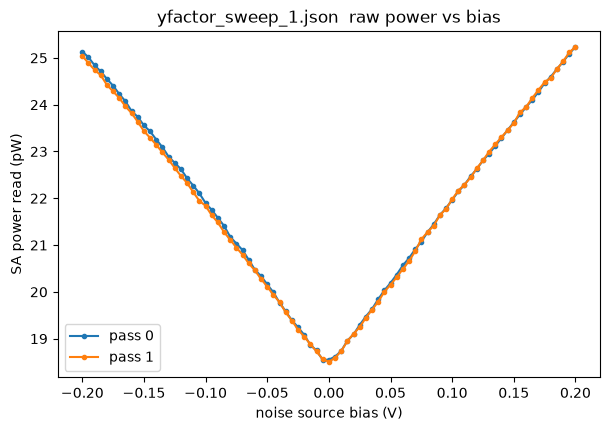

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for k in passes:
    m = pass_no == k
    ax.plot(bias[m], power[m] * 1e12, "o-", ms=3, label=f"pass {k}")
ax.set_xlabel("noise source bias (V)")
ax.set_ylabel("SA power read (pW)")
ax.set_title(f"{DATA_FILE}  raw power vs bias")
ax.legend()
plt.show()

## Hot-wire temperature vs bias

In [17]:
G = 10 ** (G_DB / 10)
L = 10 ** (WIRE_LOSS_DB / 10)
T_half = h * f / (2 * kB)                     # hf/2k_B

T_sys = power * 10 ** (LOG_VBW_CORR_DB / 10) / (kB * ENBW_HZ * G)
TN0 = T_half / np.tanh(T_half / T_WIRE0_K)    # wire noise temperature at zero bias

TN_wire = np.zeros_like(T_sys)
for k in passes:
    m = pass_no == k
    i0 = np.argmin(np.abs(bias[m]))
    TN_wire[m] = TN0 + L * (T_sys[m] - T_sys[m][i0])

# electron temperature from TN = T_half coth(T_half / Te); points below the zero-point floor are noise -> nan
Te_wire = np.full_like(TN_wire, np.nan)
ok = TN_wire > T_half
Te_wire[ok] = T_half / np.arctanh(T_half / TN_wire[ok])

for k in passes:
    m = pass_no == k
    i0 = np.argmin(np.abs(bias[m]))
    imax = np.argmax(np.abs(bias[m]))
    print(f"pass {k}: T_sys(0) = {T_sys[m][i0]:.3f} K, "
          f"T_e(|V| = {abs(bias[m][imax]):g} V) = {Te_wire[m][imax]:.3f} K")
print(f"hf/2k_B = {T_half*1e3:.1f} mK, {np.sum(~ok)} point(s) below it")

pass 0: T_sys(0) = 8.889 K, T_e(|V| = 0.2 V) = 3.288 K
pass 1: T_sys(0) = 8.868 K, T_e(|V| = 0.2 V) = 3.357 K
hf/2k_B = 133.8 mK, 1 point(s) below it


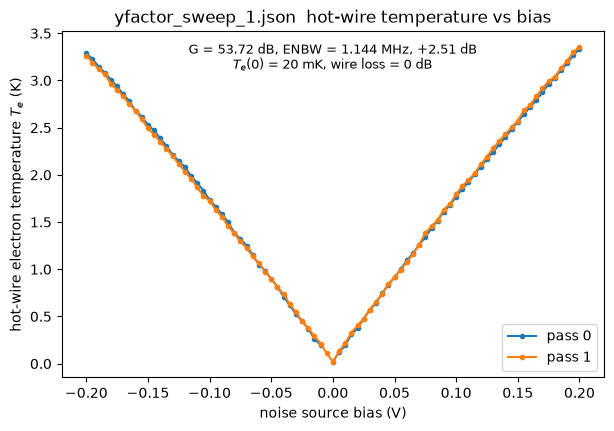

In [18]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for k in passes:
    m = pass_no == k
    ax.plot(bias[m], Te_wire[m], "o-", ms=3, label=f"pass {k}")
ax.set_xlabel("noise source bias (V)")
ax.set_ylabel("hot-wire electron temperature $T_e$ (K)")
ax.set_title(f"{DATA_FILE}  hot-wire temperature vs bias")
ax.text(0.5, 0.97, f"G = {G_DB} dB, ENBW = {ENBW_HZ/1e6:g} MHz, +{LOG_VBW_CORR_DB} dB\n"
        f"$T_e(0)$ = {T_WIRE0_K*1e3:g} mK, wire loss = {WIRE_LOSS_DB:g} dB",
        transform=ax.transAxes, ha="center", va="top", fontsize=9)
ax.legend(loc="lower right")
plt.show()